# 1_vlm_scale_pred

This notebook performs the metric scale estimation stage of the `image2bipv` pipeline.

It reads facade images and rectified outputs from notebook 0, queries a vision-language model (VLM), and predicts:

- number of floors
- facade height in meters
- facade width in meters

## Inputs

Expected inputs come from:

- `../data/demo/input/images/`
- `../outputs/0_dust3r_outputs/rectified/`
- `../outputs/0_dust3r_outputs/tables/dust3r_rectification_results.csv`

## Outputs

This notebook writes results to:

- `../outputs/1_vlm_preds/vlm_predictions.csv`

These outputs are used later by:

- `2_generate_bipv_retrofit.ipynb`
- `3_solar_energy.ipynb`

In [1]:
# Standard library
import os
import re
import json
import time
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Imaging / display
from PIL import Image
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [2]:
# -----------------------------------------------------------------------------
# Repository-relative paths
# -----------------------------------------------------------------------------

REPO_ROOT = Path("..").resolve()

DATA_DIR = REPO_ROOT / "data" / "demo" / "input"
OUTPUT0_DIR = REPO_ROOT / "outputs" / "0_dust3r_outputs"
OUTPUT1_DIR = REPO_ROOT / "outputs" / "1_vlm_preds"
CACHE_DIR = OUTPUT1_DIR / "cache"

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
METADATA_CSV = DATA_DIR / "metadata.csv"

RECTIFIED_DIR = OUTPUT0_DIR / "rectified"
RECTIFICATION_RESULTS_CSV = OUTPUT0_DIR / "tables" / "dust3r_rectification_results.csv"

OUTPUT1_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_CSV = OUTPUT1_DIR / "vlm_predictions.csv"

print("REPO_ROOT:", REPO_ROOT)
print("IMAGES_DIR:", IMAGES_DIR)
print("RECTIFIED_DIR:", RECTIFIED_DIR)
print("RECTIFICATION_RESULTS_CSV:", RECTIFICATION_RESULTS_CSV)
print("PREDICTIONS_CSV:", PREDICTIONS_CSV)

REPO_ROOT: D:\facade2dim\image2bipv
IMAGES_DIR: D:\facade2dim\image2bipv\data\demo\input\images
RECTIFIED_DIR: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified
RECTIFICATION_RESULTS_CSV: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\tables\dust3r_rectification_results.csv
PREDICTIONS_CSV: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_predictions.csv


In [3]:
# -----------------------------------------------------------------------------
# Secrets: environment variables only
# -----------------------------------------------------------------------------

def require_env(name: str) -> str:
    value = os.getenv(name)
    if not value:
        raise EnvironmentError(f"Missing required environment variable: {name}")
    return value

In [4]:
# -----------------------------------------------------------------------------
# Select VLM provider
# -----------------------------------------------------------------------------
# Options:
# - "openai"
# - "gemini"
# -----------------------------------------------------------------------------

VLM_PROVIDER = "openai"   # change to "openai" if needed
MODEL_NAME = (
    "gemini-2.5-flash-lite"
    if VLM_PROVIDER == "gemini"
    else "gpt-4o"
)

print("VLM_PROVIDER:", VLM_PROVIDER)
print("MODEL_NAME:", MODEL_NAME)

VLM_PROVIDER: openai
MODEL_NAME: gpt-4o


In [5]:
# -----------------------------------------------------------------------------
# API client setup
# -----------------------------------------------------------------------------

client = None

if VLM_PROVIDER == "openai":
    from openai import OpenAI
    client = OpenAI(api_key=require_env("OPENAI_API_KEY"))
    print("OpenAI client initialized.")

elif VLM_PROVIDER == "gemini":
    from google import genai
    client = genai.Client(api_key=require_env("GOOGLE_API_KEY"))
    print("Gemini client initialized.")

else:
    raise ValueError("VLM_PROVIDER must be either 'openai' or 'gemini'.")

OpenAI client initialized.


In [6]:
# -----------------------------------------------------------------------------
# Validate upstream outputs
# -----------------------------------------------------------------------------

if not RECTIFIED_DIR.exists():
    raise FileNotFoundError(f"Rectified image directory not found: {RECTIFIED_DIR}")

if not RECTIFICATION_RESULTS_CSV.exists():
    raise FileNotFoundError(
        f"Notebook 0 results CSV not found: {RECTIFICATION_RESULTS_CSV}"
    )

In [7]:
# -----------------------------------------------------------------------------
# Validate upstream outputs
# -----------------------------------------------------------------------------

if not RECTIFIED_DIR.exists():
    raise FileNotFoundError(f"Rectified image directory not found: {RECTIFIED_DIR}")

if not RECTIFICATION_RESULTS_CSV.exists():
    raise FileNotFoundError(
        f"Notebook 0 results CSV not found: {RECTIFICATION_RESULTS_CSV}"
    )

In [8]:
# -----------------------------------------------------------------------------
# Load notebook 0 outputs
# -----------------------------------------------------------------------------

rect_df = pd.read_csv(RECTIFICATION_RESULTS_CSV)
print(f"Loaded {len(rect_df)} rectification rows.")
display(rect_df.head())

Loaded 18 rectification rows.


,facade_id,facade_version,selected_image,mask_file,K11,K12,K13,K21,K22,K23,K31,K32,K33,Rt11,Rt12,Rt13,Rt14,Rt21,Rt22,Rt23,Rt24,Rt31,Rt32,Rt33,Rt34,po_x,po_y,po_z,h_x,h_y,h_z,v_x,v_y,v_z,normal_x,normal_y,normal_z,gravity_x,gravity_y,gravity_z,min_x,max_x,min_y,max_y,W_pred,H_pred,H_orig,W_orig,predicted_width,predicted_height,rectified_image,comparison_plot,pointcloud_file,runtime_s
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1.png,405.183746,0.0,320.0,0.0,405.183746,320.0,0.0,0.0,1.0,0.853899,-0.036141,-0.519182,0.182249,0.056741,0.998104,0.023843,-0.003079,0.517336,-0.049818,0.854331,0.000146,-0.059556,-0.000280,0.267655,-0.844631,0.033876,0.534275,0.004364,0.998398,-0.056405,0.535330,0.045310,0.843427,0.002316,-0.997755,0.066925,-0.163742,0.152957,-0.041035,0.052476,792,234,640,640,0.316699,0.093511,142728_0_v1_rectified.png,142728_0_v1_comparison.png,142728_0_v1_rgb_tinted_pcd.ply,14.662085
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1.png,388.484222,0.0,320.0,0.0,388.484222,320.0,0.0,0.0,1.0,0.999802,0.011490,-0.016267,0.000000,-0.011245,0.999823,0.015113,0.000000,0.016438,-0.014927,0.999754,0.000000,0.007141,-0.032810,0.164005,-0.993846,-0.014222,0.109851,-0.016024,0.999751,-0.015542,0.109603,0.017207,0.993827,0.020125,-0.998401,0.052819,-0.107609,0.155638,-0.040362,0.072742,658,283,640,640,0.263247,0.113104,142767_0_v1_rectified.png,142767_0_v1_comparison.png,142767_0_v1_rgb_tinted_pcd.ply,12.861162
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1.png,333.737488,0.0,320.0,0.0,333.737488,320.0,0.0,0.0,1.0,0.894083,-0.172214,-0.413471,0.197776,0.162903,0.984937,-0.057974,-0.001978,0.417227,-0.015522,0.908670,0.000062,-0.101016,-0.013845,0.235024,-0.892920,0.173869,0.415287,-0.009390,0.915026,-0.403285,0.450118,0.364001,0.815413,0.009022,-0.915323,0.402619,-0.102327,0.090999,-0.139500,0.133211,483,682,640,640,0.193327,0.272711,147978_0_v1_rectified.png,147978_0_v1_comparison.png,147978_0_v1_rgb_tinted_pcd.ply,13.488710
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2.png,324.564423,0.0,320.0,0.0,324.564423,320.0,0.0,0.0,1.0,0.999958,0.007858,-0.004767,0.000000,-0.007939,0.999822,-0.017096,0.000000,0.004632,0.017133,0.999842,0.000000,-0.065266,-0.024020,0.212733,-0.991448,0.050170,0.120472,-0.004821,0.908438,-0.417991,0.130412,0.414997,0.900428,0.008916,-0.894951,0.446075,-0.111845,0.139693,-0.207703,0.146754,629,886,640,640,0.251538,0.354457,148455_0_v2_rectified.png,148455_0_v2_comparison.png,148455_0_v2_rgb_tinted_pcd.ply,12.383121
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1.png,331.334930,0.0,320.0,0.0,331.334930,320.0,0.0,0.0,1.0,0.926754,0.169822,0.335093,-0.176860,-0.135516,0.983059,-0.123413,0.000008,-0.350375,0.068963,0.934067,0.006539,0.070722,0.015402,0.231891,-0.926539,-0.162747,-0.339173,0.005614,0.895499,-0.445028,-0.376156,0.414240,0.828802,-0.018166,-0.881174,0.472443,-0.111592,0.115923,-0.212582,0.127575,569,850,640,640,0.227515,0.340158,149099_0_v1_rectified.png,149099_0_v1_comparison.png,149099_0_v1_rgb_tinted_pcd.ply,14.189045


In [9]:
# -----------------------------------------------------------------------------
# Standardized zero-shot prompt
# -----------------------------------------------------------------------------
# This follows the manuscript prompt format.
# -----------------------------------------------------------------------------

VLM_PROMPT = """You are a visual expert trained to estimate architectural dimensions from images.
Based on the image, provide best-guess numerical estimations for the following,
in the format: floors, height_meters, width_meters.

1. How many floors does the main building facade have?
2. What is the height of the facade at the center of the image (in meters)?
3. What is the width of the facade (in meters)?

Respond only with three numbers separated by commas (e.g., 5, 15, 30).
Do not write anything else."""

In [10]:
# -----------------------------------------------------------------------------
# Parse the first three numeric values from model output
# -----------------------------------------------------------------------------

NUMBER_PATTERN = re.compile(r"[-+]?\d*\.?\d+")

def parse_vlm_response(text: str):
    """
    Extract the first three numeric tokens as:
    floors, height_m, width_m
    """
    if text is None:
        return None

    matches = NUMBER_PATTERN.findall(text)
    if len(matches) < 3:
        return None

    floors = int(round(float(matches[0])))
    height_m = float(matches[1])
    width_m = float(matches[2])

    return floors, height_m, width_m

In [11]:
# -----------------------------------------------------------------------------
# Image helpers
# -----------------------------------------------------------------------------

def load_pil_image(path: Path) -> Image.Image:
    return Image.open(path).convert("RGB")


def show_image(path: Path, figsize=(6, 6), title=None):
    img = load_pil_image(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    plt.title(title or path.name)
    plt.show()

In [18]:
# -----------------------------------------------------------------------------
# OpenAI request helper
# -----------------------------------------------------------------------------

import base64
import mimetypes

def image_file_to_data_url(image_path: Path) -> str:
    """
    Convert a local image file to a base64 data URL for the OpenAI Responses API.
    """
    mime_type, _ = mimetypes.guess_type(str(image_path))
    if mime_type is None:
        mime_type = "image/png"

    with open(image_path, "rb") as f:
        encoded = base64.b64encode(f.read()).decode("utf-8")

    return f"data:{mime_type};base64,{encoded}"


def query_openai_with_image(image_path: Path, prompt: str, model_name: str) -> str:
    """
    Send one image + one text prompt to OpenAI and return the model text output.
    """
    data_url = image_file_to_data_url(image_path)

    response = client.responses.create(
        model=model_name,
        input=[
            {
                "role": "user",
                "content": [
                    {"type": "input_text", "text": prompt},
                    {"type": "input_image", "image_url": data_url},
                ],
            }
        ],
    )

    return response.output_text

In [13]:
# -----------------------------------------------------------------------------
# Gemini request helper
# -----------------------------------------------------------------------------

def query_gemini_with_image(image_path: Path, prompt: str, model_name: str) -> str:
    img = load_pil_image(image_path)

    response = client.models.generate_content(
        model=model_name,
        contents=[prompt, img],
    )

    return response.text

In [14]:
# -----------------------------------------------------------------------------
# Unified VLM inference wrapper
# -----------------------------------------------------------------------------

def run_vlm(image_path: Path, prompt: str, provider: str, model_name: str) -> str:
    if provider == "openai":
        return query_openai_with_image(image_path, prompt, model_name)
    elif provider == "gemini":
        return query_gemini_with_image(image_path, prompt, model_name)
    else:
        raise ValueError(f"Unsupported provider: {provider}")

In [15]:
# -----------------------------------------------------------------------------
# Build candidate inference table
# -----------------------------------------------------------------------------
# We use the rectified images from notebook 0 as the main inputs.
# -----------------------------------------------------------------------------

rows = []

for _, row in rect_df.iterrows():
    rectified_name = row["rectified_image"]
    rectified_path = RECTIFIED_DIR / rectified_name

    if not rectified_path.exists():
        print(f"Missing rectified image: {rectified_path}")
        continue

    rows.append({
        "facade_id": row["facade_id"],
        "facade_version": row["facade_version"],
        "selected_image": row["selected_image"],
        "rectified_image": rectified_name,
        "rectified_path": str(rectified_path),
        "predicted_width_rel": row.get("predicted_width", np.nan),
        "predicted_height_rel": row.get("predicted_height", np.nan),
    })

vlm_input_df = pd.DataFrame(rows)
print(f"Prepared {len(vlm_input_df)} VLM input rows.")
display(vlm_input_df.head())

Prepared 18 VLM input rows.


,facade_id,facade_version,selected_image,rectified_image,rectified_path,predicted_width_rel,predicted_height_rel
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,0.316699,0.093511
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,0.263247,0.113104
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,0.193327,0.272711
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,0.251538,0.354457
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,0.227515,0.340158


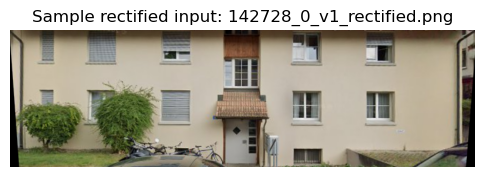

In [16]:
# -----------------------------------------------------------------------------
# Preview a sample rectified image
# -----------------------------------------------------------------------------

if len(vlm_input_df) > 0:
    sample_path = Path(vlm_input_df.iloc[0]["rectified_path"])
    show_image(sample_path, title=f"Sample rectified input: {sample_path.name}")
else:
    print("No valid VLM inputs found.")

In [19]:
# -----------------------------------------------------------------------------
# Main VLM inference loop
# -----------------------------------------------------------------------------

results = []

for idx, row in vlm_input_df.iterrows():
    image_path = Path(row["rectified_path"])
    facade_id = row["facade_id"]
    facade_version = row["facade_version"]

    start = time.perf_counter()

    raw_response = None
    error_message = None
    floors, height_m, width_m = None, None, None
    parse_status = None

    try:
        raw_response = run_vlm(
            image_path=image_path,
            prompt=VLM_PROMPT,
            provider=VLM_PROVIDER,
            model_name=MODEL_NAME,
        )

        parsed = parse_vlm_response(raw_response)

        if parsed is None:
            parse_status = "parse_error"
        else:
            floors, height_m, width_m = parsed
            parse_status = "ok"

    except Exception as e:
        error_message = repr(e)
        parse_status = "request_error"

    runtime_s = time.perf_counter() - start

    results.append({
        "facade_id": facade_id,
        "facade_version": facade_version,
        "selected_image": row["selected_image"],
        "rectified_image": row["rectified_image"],
        "provider": VLM_PROVIDER,
        "model_name": MODEL_NAME,
        "raw_response": raw_response,
        "error_message": error_message,
        "parse_status": parse_status,
        "pred_floors": floors,
        "pred_height_m": height_m,
        "pred_width_m": width_m,
        "runtime_s": runtime_s,
    })

    print(
        f"[{idx+1}/{len(vlm_input_df)}] {facade_id} "
        f"status={parse_status} floors={floors} h={height_m} w={width_m}"
    )
    if error_message is not None:
        print("   error:", error_message)

[1/18] 142728_0 status=ok floors=2 h=6.0 w=15.0
[2/18] 142767_0 status=ok floors=1 h=4.0 w=12.0
[3/18] 147978_0 status=ok floors=5 h=15.0 w=10.0
[4/18] 148455_0 status=ok floors=6 h=18.0 w=20.0
[5/18] 149099_0 status=ok floors=6 h=18.0 w=20.0
[6/18] 149224_0 status=ok floors=6 h=18.0 w=20.0
[7/18] 151360_0 status=ok floors=3 h=9.0 w=15.0
[8/18] 153087_0 status=ok floors=3 h=9.0 w=12.0
[9/18] 2373854_0 status=ok floors=1 h=6.0 w=8.0
[10/18] 302019085_0 status=ok floors=2 h=6.0 w=10.0
[11/18] 302019622_0 status=ok floors=4 h=12.0 w=15.0
[12/18] 302019911_0 status=ok floors=4 h=12.0 w=20.0
[13/18] 302019985_0 status=ok floors=5 h=15.0 w=12.0
[14/18] 302020108_0 status=ok floors=3 h=9.0 w=18.0
[15/18] 302020562_0 status=ok floors=4 h=12.0 w=20.0
[16/18] 302034409_0 status=ok floors=3 h=10.0 w=12.0
[17/18] 302064053_0 status=ok floors=4 h=12.0 w=15.0
[18/18] 302065471_0 status=ok floors=2 h=6.0 w=12.0


In [20]:
# -----------------------------------------------------------------------------
# Save predictions
# -----------------------------------------------------------------------------

pred_df = pd.DataFrame(results)
pred_df.to_csv(PREDICTIONS_CSV, index=False)

print(f"Saved predictions to: {PREDICTIONS_CSV}")
display(pred_df.head())

Saved predictions to: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_predictions.csv


,facade_id,facade_version,selected_image,rectified_image,provider,model_name,raw_response,error_message,parse_status,pred_floors,pred_height_m,pred_width_m,runtime_s
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1_rectified.png,openai,gpt-4o,"2, 6, 15",None,ok,2,6.0,15.0,1.937140
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1_rectified.png,openai,gpt-4o,"1, 4, 12",None,ok,1,4.0,12.0,2.738097
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1_rectified.png,openai,gpt-4o,"5, 15, 10",None,ok,5,15.0,10.0,2.774974
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2_rectified.png,openai,gpt-4o,"6, 18, 20",None,ok,6,18.0,20.0,2.919499
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1_rectified.png,openai,gpt-4o,"6, 18, 20",None,ok,6,18.0,20.0,2.913607


In [21]:
# -----------------------------------------------------------------------------
# Quick quality summary
# -----------------------------------------------------------------------------

if len(pred_df) > 0:
    summary = {
        "n_rows": len(pred_df),
        "n_ok": int((pred_df["parse_status"] == "ok").sum()),
        "n_failed": int((pred_df["parse_status"] != "ok").sum()),
        "fail_rate_percent": 100 * (pred_df["parse_status"] != "ok").mean(),
        "mean_runtime_s": pred_df["runtime_s"].mean(),
    }

    print(json.dumps(summary, indent=2))
else:
    print("No prediction rows to summarize.")

{
  "n_rows": 18,
  "n_ok": 18,
  "n_failed": 0,
  "fail_rate_percent": 0.0,
  "mean_runtime_s": 2.225995233372992
}


In [22]:
# -----------------------------------------------------------------------------
# Merge with notebook 0 geometry outputs
# -----------------------------------------------------------------------------

merged_df = rect_df.merge(
    pred_df,
    on=["facade_id", "facade_version", "selected_image", "rectified_image"],
    how="left",
)

MERGED_OUTPUT_CSV = OUTPUT1_DIR / "vlm_predictions_merged_with_rectification.csv"
merged_df.to_csv(MERGED_OUTPUT_CSV, index=False)

print(f"Saved merged outputs to: {MERGED_OUTPUT_CSV}")
display(merged_df.head())

Saved merged outputs to: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_predictions_merged_with_rectification.csv


,facade_id,facade_version,selected_image,mask_file,K11,K12,K13,K21,K22,K23,K31,K32,K33,Rt11,Rt12,Rt13,Rt14,Rt21,Rt22,Rt23,Rt24,Rt31,Rt32,Rt33,Rt34,po_x,po_y,po_z,h_x,h_y,h_z,v_x,v_y,v_z,normal_x,normal_y,normal_z,gravity_x,gravity_y,gravity_z,min_x,max_x,min_y,max_y,W_pred,H_pred,H_orig,W_orig,predicted_width,predicted_height,rectified_image,comparison_plot,pointcloud_file,runtime_s_x,provider,model_name,raw_response,error_message,parse_status,pred_floors,pred_height_m,pred_width_m,runtime_s_y
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1.png,405.183746,0.0,320.0,0.0,405.183746,320.0,0.0,0.0,1.0,0.853899,-0.036141,-0.519182,0.182249,0.056741,0.998104,0.023843,-0.003079,0.517336,-0.049818,0.854331,0.000146,-0.059556,-0.000280,0.267655,-0.844631,0.033876,0.534275,0.004364,0.998398,-0.056405,0.535330,0.045310,0.843427,0.002316,-0.997755,0.066925,-0.163742,0.152957,-0.041035,0.052476,792,234,640,640,0.316699,0.093511,142728_0_v1_rectified.png,142728_0_v1_comparison.png,142728_0_v1_rgb_tinted_pcd.ply,14.662085,openai,gpt-4o,"2, 6, 15",None,ok,2,6.0,15.0,1.937140
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1.png,388.484222,0.0,320.0,0.0,388.484222,320.0,0.0,0.0,1.0,0.999802,0.011490,-0.016267,0.000000,-0.011245,0.999823,0.015113,0.000000,0.016438,-0.014927,0.999754,0.000000,0.007141,-0.032810,0.164005,-0.993846,-0.014222,0.109851,-0.016024,0.999751,-0.015542,0.109603,0.017207,0.993827,0.020125,-0.998401,0.052819,-0.107609,0.155638,-0.040362,0.072742,658,283,640,640,0.263247,0.113104,142767_0_v1_rectified.png,142767_0_v1_comparison.png,142767_0_v1_rgb_tinted_pcd.ply,12.861162,openai,gpt-4o,"1, 4, 12",None,ok,1,4.0,12.0,2.738097
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1.png,333.737488,0.0,320.0,0.0,333.737488,320.0,0.0,0.0,1.0,0.894083,-0.172214,-0.413471,0.197776,0.162903,0.984937,-0.057974,-0.001978,0.417227,-0.015522,0.908670,0.000062,-0.101016,-0.013845,0.235024,-0.892920,0.173869,0.415287,-0.009390,0.915026,-0.403285,0.450118,0.364001,0.815413,0.009022,-0.915323,0.402619,-0.102327,0.090999,-0.139500,0.133211,483,682,640,640,0.193327,0.272711,147978_0_v1_rectified.png,147978_0_v1_comparison.png,147978_0_v1_rgb_tinted_pcd.ply,13.488710,openai,gpt-4o,"5, 15, 10",None,ok,5,15.0,10.0,2.774974
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2.png,324.564423,0.0,320.0,0.0,324.564423,320.0,0.0,0.0,1.0,0.999958,0.007858,-0.004767,0.000000,-0.007939,0.999822,-0.017096,0.000000,0.004632,0.017133,0.999842,0.000000,-0.065266,-0.024020,0.212733,-0.991448,0.050170,0.120472,-0.004821,0.908438,-0.417991,0.130412,0.414997,0.900428,0.008916,-0.894951,0.446075,-0.111845,0.139693,-0.207703,0.146754,629,886,640,640,0.251538,0.354457,148455_0_v2_rectified.png,148455_0_v2_comparison.png,148455_0_v2_rgb_tinted_pcd.ply,12.383121,openai,gpt-4o,"6, 18, 20",None,ok,6,18.0,20.0,2.919499
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1.png,331.334930,0.0,320.0,0.0,331.334930,320.0,0.0,0.0,1.0,0.926754,0.169822,0.335093,-0.176860,-0.135516,0.983059,-0.123413,0.000008,-0.350375,0.068963,0.934067,0.006539,0.070722,0.015402,0.231891,-0.926539,-0.162747,-0.339173,0.005614,0.895499,-0.445028,-0.376156,0.414240,0.828802,-0.018166,-0.881174,0.472443,-0.111592,0.115923,-0.212582,0.127575,569,850,640,640,0.227515,0.340158,149099_0_v1_rectified.png,149099_0_v1_comparison.png,149099_0_v1_rgb_tinted_pcd.ply,14.189045,openai,gpt-4o,"6, 18, 20",None,ok,6,18.0,20.0,2.913607


In [23]:
# -----------------------------------------------------------------------------
# Scaling anchor table
# -----------------------------------------------------------------------------
# The paper notes that predicted height is used as the scaling anchor.
# -----------------------------------------------------------------------------

anchor_df = pred_df.copy()
anchor_df = anchor_df[anchor_df["parse_status"] == "ok"].copy()

ANCHOR_CSV = OUTPUT1_DIR / "vlm_scaling_anchor.csv"
anchor_df.to_csv(ANCHOR_CSV, index=False)

print(f"Saved scaling anchor table to: {ANCHOR_CSV}")

Saved scaling anchor table to: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_scaling_anchor.csv
